## Nome: Caio Semblano Silva
## Matrícula: 621

## Atividade 13 – Análise dos Tempos de Resposta em uma Rede de Sensores Industriais

Uma equipe de engenharia está avaliando o desempenho de uma rede de sensores utilizada para monitorar variáveis de uma planta industrial. Nesse sistema, módulos embarcados enviam informações para uma estação central, que confirma o recebimento de cada mensagem.

Durante os ensaios, foram avaliados **20 módulos de telemetria** sob condições de teste semelhantes. Para cada módulo, a equipe registrou a **latência média de comunicação (em milissegundos)**, isto é, o tempo médio entre o envio de uma mensagem e a confirmação de seu recebimento. Os dados são **simulados para fins didáticos**.

A equipe deseja compreender o comportamento típico da comunicação e identificar possíveis diferenças de desempenho entre os módulos. Como referência do projeto, considera-se desejável uma latência média de até **130 ms** por módulo. Tempos elevados podem afetar a atualização das informações de monitoramento, mas conclusões sobre suas causas exigem investigação técnica adicional.

Utilize os dados da tabela a seguir para realizar as análises estatísticas propostas:

| Módulo de Telemetria | Latência Média (ms) |
|---------------------|--------------------|
| Módulo 01           | 104                |
| Módulo 02           | 111                |
| Módulo 03           | 116                |
| Módulo 04           | 109                |
| Módulo 05           | 113                |
| Módulo 06           | 76                 |
| Módulo 07           | 129                |
| Módulo 08           | 110                |
| Módulo 09           | 115                |
| Módulo 10           | 121                |
| Módulo 11           | 83                 |
| Módulo 12           | 182                |
| Módulo 13           | 108                |
| Módulo 14           | 93                 |
| Módulo 15           | 116                |
| Módulo 16           | 107                |
| Módulo 17           | 88                 |
| Módulo 18           | 112                |
| Módulo 19           | 119                |
| Módulo 20           | 125                |


In [1]:
%matplotlib inline

# Bibliotecas para visualização dos resultados
import seaborn as sns
import matplotlib.pyplot as plt

# Bibliotecas para análise estatística das medições
import numpy as np
import pandas as pd

In [2]:
# Dados simulados dos ensaios de latência dos módulos de telemetria
# Cada valor representa a latência média registrada para um módulo, em ms.
tabela = {
    "Módulo de Telemetria": [
        "Módulo 01", "Módulo 02", "Módulo 03", "Módulo 04", "Módulo 05",
        "Módulo 06", "Módulo 07", "Módulo 08", "Módulo 09", "Módulo 10",
        "Módulo 11", "Módulo 12", "Módulo 13", "Módulo 14", "Módulo 15",
        "Módulo 16", "Módulo 17", "Módulo 18", "Módulo 19", "Módulo 20"
    ],
    "Latência Média (ms)": [
        104, 111, 116, 109, 113, 76, 129, 110, 115, 121,
        83, 182, 108, 93, 116, 107, 88, 112, 119, 125
    ]
}

dados = pd.DataFrame(tabela)
print(dados)

   Módulo de Telemetria  Latência Média (ms)
0             Módulo 01                  104
1             Módulo 02                  111
2             Módulo 03                  116
3             Módulo 04                  109
4             Módulo 05                  113
5             Módulo 06                   76
6             Módulo 07                  129
7             Módulo 08                  110
8             Módulo 09                  115
9             Módulo 10                  121
10            Módulo 11                   83
11            Módulo 12                  182
12            Módulo 13                  108
13            Módulo 14                   93
14            Módulo 15                  116
15            Módulo 16                  107
16            Módulo 17                   88
17            Módulo 18                  112
18            Módulo 19                  119
19            Módulo 20                  125


---
### Parte 1 - Tendência Central e Interpretação

Obs.: Se necessário, ordene os valores de latência em ordem crescente ou decrescente (rol).

In [3]:
# Ordenar os módulos por latência média de comunicação (crescente)
df_ordenado = dados.sort_values(by='Latência Média (ms)', ascending=True).reset_index(drop=True)

# Média das latências medidas
media = dados['Latência Média (ms)'].mean()

# Mediana das latências medidas
mediana = dados['Latência Média (ms)'].median()

# Moda das latências (a série pode apresentar mais de uma moda)
moda = dados['Latência Média (ms)'].mode()

1. Calcule a média, a mediana e a moda dos tempos médios de resposta dos 20 módulos de telemetria. Apresente os resultados em milissegundos (ms).
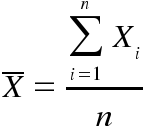
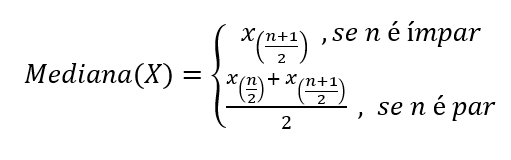


In [4]:
print(df_ordenado)
print()
print("Média:", round(media, 2), "ms")
print("Mediana:", mediana, "ms")
print("Moda:", moda.iloc[0], "ms")
print()

desvios = dados.copy()
desvios["distância da média"] = abs(desvios["Latência Média (ms)"] - media)
desvios = desvios.sort_values("distância da média", ascending=False)
print(desvios.head(4))

   Módulo de Telemetria  Latência Média (ms)
0             Módulo 06                   76
1             Módulo 11                   83
2             Módulo 17                   88
3             Módulo 14                   93
4             Módulo 01                  104
5             Módulo 16                  107
6             Módulo 13                  108
7             Módulo 04                  109
8             Módulo 08                  110
9             Módulo 02                  111
10            Módulo 18                  112
11            Módulo 05                  113
12            Módulo 09                  115
13            Módulo 03                  116
14            Módulo 15                  116
15            Módulo 19                  119
16            Módulo 10                  121
17            Módulo 20                  125
18            Módulo 07                  129
19            Módulo 12                  182

Média: 111.85 ms
Mediana: 111.5 ms
Moda: 116 ms

   Mó

2. Os valores obtidos para média, mediana e moda são próximos? Qual dessas medidas representa melhor o desempenho típico de comunicação dos módulos analisados? Justifique com base nos resultados.

*Resposta*:

A média deu 111,85 ms e a mediana 111,5 ms, bem perto uma da outra. A moda ficou em 116 ms, um pouco mais alta, mas isso só aconteceu porque dois módulos empataram nesse valor. Com 20 medições e quase tudo diferente, a moda não ajuda muito.

A mediana representa melhor o desempenho típico. A média sofre com os extremos, principalmente o Módulo 12 (182 ms), que puxa o valor pra cima, e um pouco também com os módulos bem rápidos (76 ms e 83 ms).

3. Identifique os módulos cujas latências estão mais distantes da média do conjunto. O que esses resultados podem indicar sobre o desempenho dos módulos e quais fatores técnicos poderiam ser investigados?

Resposta:

Os mais distantes da média (111,85 ms) são o Módulo 12, com 182 ms (cerca de 70 ms acima), e o Módulo 06, com 76 ms (uns 36 ms abaixo). Depois vêm o Módulo 11 (83 ms) e o Módulo 17 (88 ms).

O Módulo 12 está bem mais lento que o resto e passa do requisito de 130 ms. Pode ser problema de rede, retransmissão, interferência ou até o próprio hardware. Os três mais rápidos (06, 11 e 17) podem estar mais perto da estação, com menos carga ou firmware diferente. Sem olhar o ensaio em si, isso só aponta quem merece investigação, não a causa.

---
### Parte 2 – Separatrizes (Quartis)

In [5]:
# Cálculo dos quartis das latências médias de comunicação
quartis = dados['Latência Média (ms)'].quantile([0.25, 0.5, 0.75])

4. Calcule os quartis Q1, Q2 (mediana) e Q3 das latências médias dos módulos. Apresente os valores em milissegundos (ms).
<br>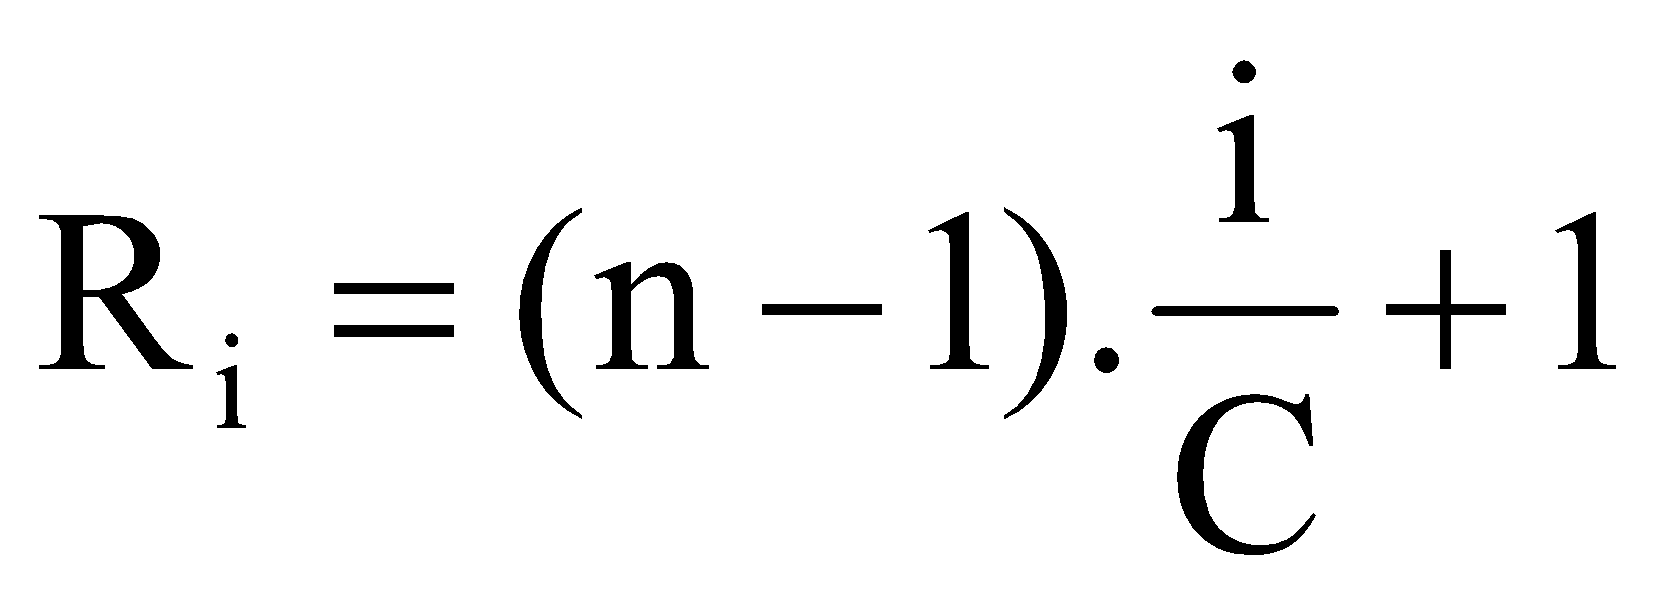

In [6]:
print("Q1 =", quartis[0.25], "ms")
print("Q2 =", quartis[0.5], "ms")
print("Q3 =", quartis[0.75], "ms")
print()

q1 = quartis[0.25]
q3 = quartis[0.75]

print("Abaixo de Q1:")
print(dados[dados["Latência Média (ms)"] < q1])
print()
print("Acima de Q3:")
print(dados[dados["Latência Média (ms)"] > q3])

Q1 = 106.25 ms
Q2 = 111.5 ms
Q3 = 116.75 ms

Abaixo de Q1:
   Módulo de Telemetria  Latência Média (ms)
0             Módulo 01                  104
5             Módulo 06                   76
10            Módulo 11                   83
13            Módulo 14                   93
16            Módulo 17                   88

Acima de Q3:
   Módulo de Telemetria  Latência Média (ms)
6             Módulo 07                  129
9             Módulo 10                  121
11            Módulo 12                  182
18            Módulo 19                  119
19            Módulo 20                  125


5. Quais módulos apresentam latências abaixo de Q1? O que esse resultado representa em termos de rapidez de comunicação?

Resposta:

Ficaram abaixo de Q1 (106,25 ms) o Módulo 06 (76 ms), o 11 (83 ms), o 17 (88 ms), o 14 (93 ms) e o 01 (104 ms). São os 25% mais rápidos da amostra.

Na prática isso é comunicação boa: a confirmação chega cedo. Não significa que os outros estejam ruins, só que esses cinco respondem mais rápido que o restante.

6. Quais módulos apresentam latências acima de Q3? Explique por que esses módulos podem exigir uma análise adicional do sistema de comunicação.

Resposta:

Acima de Q3 (116,75 ms) ficaram o Módulo 19 (119 ms), o 10 (121 ms), o 20 (125 ms), o 07 (129 ms) e o 12 (182 ms). São os 25% mais lentos da amostra.

O Módulo 12 dispara dos outros e o 07 já encosta nos 130 ms do projeto. Esses casos pedem uma olhada extra: tráfego, ruído, distância, buffer, retransmissão. Se a latência alta for frequente, o monitoramento pode atrasar.

---
### Parte 3 – Dispersão

In [7]:
# Amplitude das latências: maior valor menos menor valor (ms)
latencias = dados['Latência Média (ms)']
amplitude = max(latencias) - min(latencias)

# Função para calcular a variância amostral das latências (ms²)
def variancia_latencia(valores):
    media = sum(valores) / len(valores)
    return sum((x - media) ** 2 for x in valores) / (len(valores) - 1)

# Função para calcular o desvio-padrão amostral das latências (ms)
def desvio_padrao_latencia(valores):
    return variancia_latencia(valores) ** 0.5

7. Calcule as seguintes medidas de dispersão para as latências médias dos módulos:

- Amplitude (ms):
<br>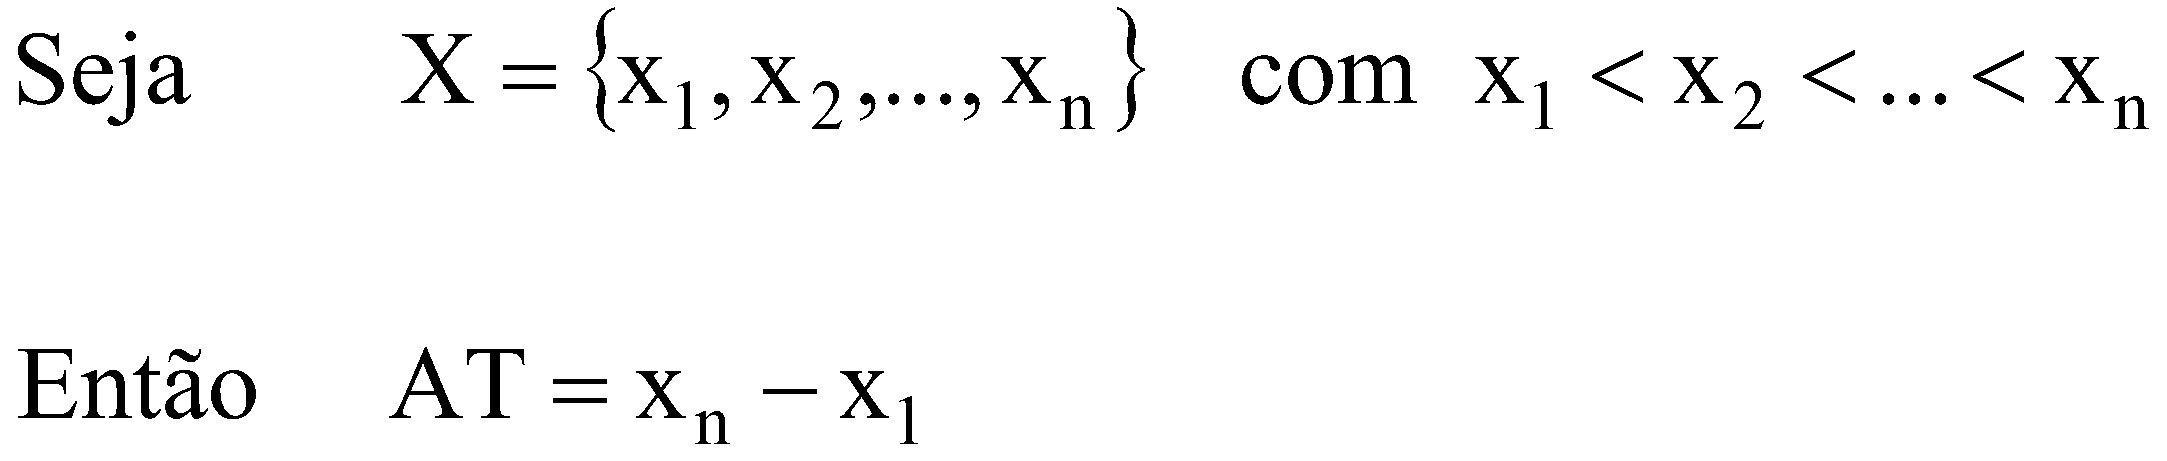

In [8]:
print("Amplitude:", amplitude, "ms")
print("Maior latência:", latencias.max(), "ms")
print("Menor latência:", latencias.min(), "ms")

Amplitude: 106 ms
Maior latência: 182 ms
Menor latência: 76 ms


- Variância (amostral, em ms²):
<br>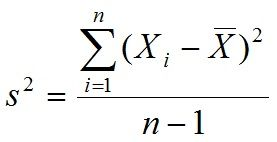

In [9]:
variancia = variancia_latencia(latencias)
print("Variância amostral:", round(variancia, 2), "ms²")

Variância amostral: 459.08 ms²


- Desvio Padrão (amostral, em ms):
<br>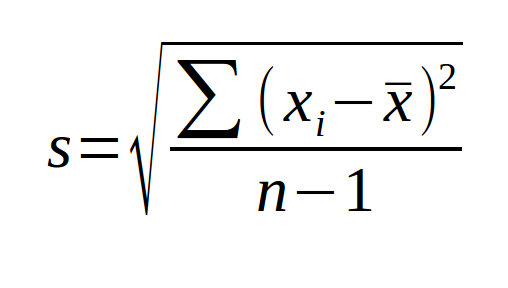


In [10]:
desvio = desvio_padrao_latencia(latencias)
print("Desvio padrão amostral:", round(desvio, 2), "ms")

Desvio padrão amostral: 21.43 ms


8. As latências variam muito entre os módulos? Como essa dispersão pode influenciar a escolha de dispositivos, o diagnóstico de falhas e a confiabilidade do monitoramento industrial? Justifique com base nas medidas calculadas.

Resposta:

A amplitude deu 106 ms, o que parece muita variação (de 76 ms até 182 ms). O desvio padrão ficou em cerca de 21,4 ms, uns 19% da média. Só que o intervalo interquartil é 10,5 ms: o miolo da amostra está concentrado entre 106,25 ms e 116,75 ms. A dispersão grande vem principalmente do Módulo 12, e um pouco dos módulos muito rápidos.

Na escolha do dispositivo, um lote com essa cara é irregular. Pro diagnóstico, o desvio padrão sozinho assusta, mas Q1 e Q3 mostram que a maioria está ok e o problema é pontual. A confiabilidade do monitoramento sofre se um módulo como o 12 atrasar a atualização; os outros, em torno de 110 ms, cabem no requisito de 130 ms.

---
### Parte 4 – Visualização de Dados

In [11]:
# Função para visualizar a distribuição das latências por histograma
def plot_histograma_latencia(dados, coluna='Latência Média (ms)', bins=10):
    """
    Plota um histograma das latências registradas nos módulos.
    :param dados: DataFrame com os resultados dos ensaios
    :param coluna: Nome da coluna de latências, em milissegundos
    :param bins: Número de intervalos do histograma
    """
    plt.figure(figsize=(8, 5))
    plt.hist(dados[coluna], bins=bins, color='skyblue', edgecolor='black')
    plt.title('Distribuição das latências dos módulos de telemetria')
    plt.xlabel('Latência média de comunicação (ms)')
    plt.ylabel('Quantidade de módulos')
    plt.axvline(dados[coluna].mean(), color='red', linestyle='--',
                label=f'Média: {dados[coluna].mean():.2f} ms')
    plt.legend()
    plt.show()

# Função para visualizar a dispersão das latências por boxplot
def plot_boxplot_latencia(dados, coluna='Latência Média (ms)'):
    """
    Plota um boxplot para observar quartis, mediana e possíveis outliers.
    :param dados: DataFrame com os resultados dos ensaios
    :param coluna: Nome da coluna de latências, em milissegundos
    """
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=dados[coluna], color='lightgreen')
    plt.title('Dispersão das latências dos módulos de telemetria')
    plt.xlabel('Latência média de comunicação (ms)')
    plt.show()

9. Utilize a função `plot_histograma_latencia()` para criar um histograma da distribuição das latências médias dos 20 módulos. Observe a concentração e a dispersão dos valores.

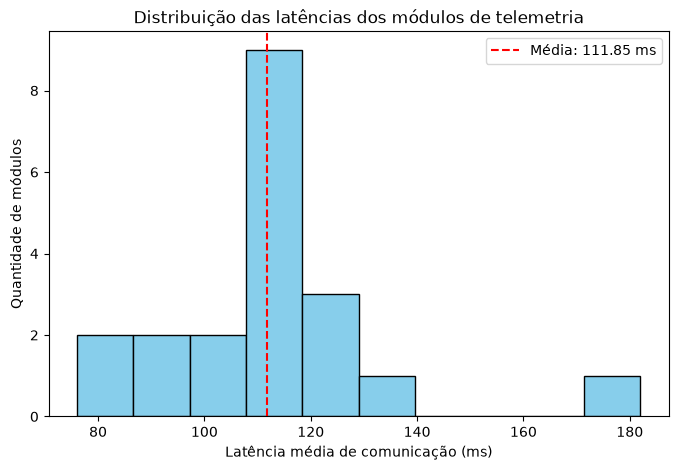

In [12]:
plot_histograma_latencia(dados)

10. Utilize a função `plot_boxplot_latencia()` para criar um boxplot das latências. Identifique visualmente os quartis, a mediana e possíveis valores atípicos (outliers).

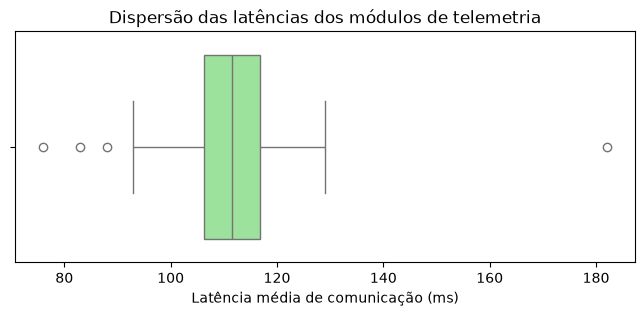

IQR: 10.5
Limite inferior: 90.5
Limite superior: 132.5

Outliers:
   Módulo de Telemetria  Latência Média (ms)
5             Módulo 06                   76
10            Módulo 11                   83
11            Módulo 12                  182
16            Módulo 17                   88


In [13]:
plot_boxplot_latencia(dados)

q1 = quartis[0.25]
q3 = quartis[0.75]
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

print("IQR:", iqr)
print("Limite inferior:", lim_inf)
print("Limite superior:", lim_sup)
print()
print("Outliers:")
print(dados[(dados["Latência Média (ms)"] < lim_inf) | (dados["Latência Média (ms)"] > lim_sup)])

11. Com base no boxplot, quais módulos podem ser considerados outliers? Explique como essas latências podem orientar a investigação de problemas de comunicação e a validação do requisito de 130 ms.

Resposta:

No boxplot os outliers são o Módulo 12 (182 ms, bem acima) e os Módulos 06 (76 ms), 11 (83 ms) e 17 (88 ms), abaixo do limite inferior de 90,5 ms. O Módulo 14 (93 ms) ficou perto, mas ainda dentro.

O 12 é o que mais importa: é o único acima de 130 ms. Vale checar cabo, interferência, carga e se o ensaio foi anômalo. Os três rápidos não violam o requisito, mas também saem do padrão e podem indicar posição melhor na planta ou configuração diferente. Tirando o 12, o restante valida o alvo de 130 ms; a mediana de 111,5 ms está folgada em relação a esse limite.